In [41]:
import os
import re
import numpy as np
import h5py
import matplotlib.pyplot as plt
from scipy.ndimage import uniform_filter1d
from scipy.stats import trim_mean, ttest_rel

In [ ]:
REPO_DIR  = "/Users/BenDobbins/Desktop/Northwestern/Lab/fmri-semantic-decoding/semantic-decoding-ecog"
data_dir  = os.path.join(REPO_DIR, "data", "SE_Processed", "FIR")      # continuous HG output
raw_dir   = os.path.join(REPO_DIR, "data")                     # BCI2000 .mat, for fs + channel names
label_dir = os.path.join(REPO_DIR, "data", "labels")           # <run>_story_words.txt

data_file = "SE_emptyTask_10_HG_all_data.mat"
run_id    = data_file.split("_HG_")[0]                         # e.g. SE_emptyTask_11

raw_file   = os.path.join(raw_dir,   run_id + ".mat")
label_file = os.path.join(label_dir, run_id + "_story_words.txt")
print(run_id)

SE_emptyTask_10


## Data layout — continuous, not epoched

`preprocessing/save_data_by_freq.m` no longer cuts trials. `all_data` is now a **1x1 cell**
holding one continuous matrix:

```
all_data{1,1}   ->   (n_samples x n_channels)   HG power, z-scored over the whole run
```

That is the format the fMRI-style decoding pipeline wants (see `decoding/utils_resp.py`), but it
means the per-trial metadata the old notebook read out of columns 2-7 — word, duration, sample
rate, channel names — **is no longer saved**. Two of those we rebuild here:

| needed | where it now comes from |
|---|---|
| sample rate | `parameters.SamplingRate.NumericValue` in the raw `data/<run>.mat` |
| channel names | `parameters.ChannelNames.Value`, then the same white-matter / `DC` removal `prepare_data.m` applies |
| word + onset/offset times | `data/labels/<run>_story_words.txt`, already in recording time |

The channel reconstruction is checked against the column count of the matrix, so if the
white-matter list in `SE_preprocessing_full.m` ever changes this cell will fail loudly rather
than silently mislabel channels.

In [43]:
# ---- white-matter channels, transcribed from cfg.whitematter in SE_preprocessing_full.m ----
_WM_SPEC = [("AC", range(2, 12)), ("Q", range(4, 12)), ("O", [10, 15]), ("M", [4]),
            ("N", [12]), ("F", [4]), ("Y", [6, 7, 8, 9, 14, 15]), ("A", [7, 8, 9]),
            ("B", range(4, 9)), ("C", range(3, 7)), ("S", [7]), ("T", [4, 6, 7, 8, 9]),
            ("L", range(4, 8)), ("W", list(range(2, 14)) + [15, 16])]
WHITEMATTER = {f"{p}{n}" for p, nums in _WM_SPEC for n in nums} | {"DC03"}
EXCLUDE_LEADS = {"DC"}


def raw_metadata(raw_path):
    """fs and post-CAR channel names, mirroring prepare_data.m."""
    with h5py.File(raw_path, "r") as f:
        fs = float(np.array(f["parameters"]["SamplingRate"]["NumericValue"]).flatten()[0])
        blob = "".join(chr(c) for c in
                       np.array(f["parameters"]["ChannelNames"]["Value"]).flatten())

    s = re.sub(r"(?<=[Ee][Mm][Gg])\s+(?=\d+-REF)", "", blob)
    s = re.sub(r"(?<=[Ee][Kk][Gg])\s+(?=\d+-REF)", "", s)
    ids = [re.sub(r"[-_]REF-?\d*$", "", t.replace("*", ""), flags=re.I)
           for t in re.findall(r"\S+", s)]

    # prepare_data.m walks leads in `unique(regexprep(ids,'\d+',''),'stable')` order and drops
    # white matter within each; since the recording order is already lead-grouped, that is the
    # same as filtering the original order.
    leads = [l for l in dict.fromkeys(re.sub(r"\d+", "", c) for c in ids)
             if l not in EXCLUDE_LEADS]
    keep = []
    for lead in leads:
        keep += [i for i, c in enumerate(ids)
                 if re.match(rf"^{lead}\d+$", c) and c not in WHITEMATTER]
    return fs, [ids[i] for i in keep]


def load_continuous(fir_path, dtype=np.float32, chunk=16):
    """all_data{1,1} -> (n_samples, n_channels). Read in channel blocks to keep peak RAM down."""
    with h5py.File(fir_path, "r") as f:
        ad = f["all_data"]
        if ad.shape != (1, 1):
            raise ValueError(f"expected a 1x1 cell (continuous format), got {ad.shape}. "
                             "This looks like an old epoched file - use SE_Processed/FIR_OLD "
                             "with the previous notebook.")
        ds = f[ad[0, 0]]                       # stored transposed: (n_channels, n_samples)
        nch, nsamp = ds.shape
        X = np.empty((nsamp, nch), dtype)
        for k0 in range(0, nch, chunk):
            k1 = min(k0 + chunk, nch)
            X[:, k0:k1] = np.asarray(ds[k0:k1, :], dtype).T
    return X


FS, CHANS = raw_metadata(raw_file)
HG = load_continuous(os.path.join(data_dir, data_file))
NCH = HG.shape[1]

if len(CHANS) != NCH:
    raise AssertionError(f"rebuilt {len(CHANS)} channel names but the matrix has {NCH} columns; "
                         "the white-matter list is out of sync with the .mat")

DUR_S = HG.shape[0] / FS
print(f"{HG.shape[0]:,} samples x {NCH} channels @ {FS:g} Hz  =  {DUR_S/60:.1f} min "
      f"({HG.nbytes/1e9:.2f} GB as {HG.dtype})")
print("channels:", ", ".join(CHANS[:12]), "...", ", ".join(CHANS[-4:]))

FileNotFoundError: [Errno 2] Unable to synchronously open file (unable to open file: name = '/Users/BenDobbins/Desktop/Northwestern/Lab/fmri-semantic-decoding/semantic-decoding-ecog/SE_Processed/FIR/SE_emptyTask_10_HG_all_data.mat', errno = 2, error message = 'No such file or directory', flags = 0, o_flags = 0)

---

# Sanity check: is the HG extraction and timing right?

**What changed.** Nothing is pre-cut any more, so the notebook does its own epoching from the
word annotations. That is *better* for checking timing: the alignment is now an explicit,
adjustable number in this notebook rather than something baked into the .mat.

**The one timing term that matters.** `extract_bandpower` uses `filter` (causal FIR), not
`filtfilt`, and the de-delay line is commented out — so the saved HG envelope **lags the neural
signal by the filter's group delay**, `floor((firorder-1)/2)` samples ~= 0.2 s at 2 kHz. The old
epoched pipeline hid this by adding `fir_delay_s` to the annotation times before cutting
(`prepare_data.m`); we do exactly the same below with `FIR_DELAY_S`. **If the response looks
shifted, this is the first thing to change** — set it to 0 and see whether things get better or
worse.

Every word is one heard word from continuous story audio, so epochs are ragged. Three ways to
line them up, each failing differently:

| alignment | how variable length is handled | what it tests |
|---|---|---|
| **onset-locked** | fixed window around word onset; offsets smear out | onset response (auditory cortex should fire here) |
| **offset-locked** | fixed window around word offset; onsets smear out | offset / word-end response |
| **piecewise time-warp** | 1 s pre in real time, word interval resampled to the *median* word duration, 1 s post in real time | both edges sharp at once — the main figure |

**Two more things that matter for listening data:**

1. This is continuous speech, so the pre-word baseline usually contains *other words*. Trials
   preceded by a real silent gap are pulled out separately (`gap_before`) — those are the ones
   that should show a textbook onset transient.
2. HG power is z-scored but still very heavy-tailed (a single artifact sample hits z > 200). A
   plain trial mean is dominated by a handful of trials, so everything below uses artifact-trial
   rejection + a **20% trimmed mean**.

In [34]:
# ---- word annotations -> sample indices in the continuous recording --------------------------
# <run>_story_words.txt is onset<TAB>offset<TAB>word, in seconds from the start of the ECoG
# recording, so no extra sync offset is needed.

# Causal-FIR group delay, matching prepare_data.m. (fir1 of order N has true group delay N/2 =
# 400 samples; the MATLAB code uses floor((N-1)/2) = 399. The 0.5 ms difference is irrelevant,
# but we keep its value so this notebook and the old epoched files agree.)
FIR_ORDER   = int(np.floor(0.4 * FS))
FIR_DELAY_S = np.floor((FIR_ORDER - 1) / 2) / FS

lab   = np.genfromtxt(label_file, dtype=None, delimiter="\t", encoding="utf-8",
                      names=("on", "off", "w"))
l_on  = lab["on"].astype(float)
l_off = lab["off"].astype(float)
l_w   = np.array([str(x) for x in lab["w"]])

# inter-word silence, from the full annotation list (before any trials are dropped)
g_before = np.r_[np.inf, l_on[1:]  - l_off[:-1]]
g_after  = np.r_[l_on[1:] - l_off[:-1], np.inf]

WIN = 0.90                                   # s of real time kept each side of the anchor
s_on_all  = (l_on  + FIR_DELAY_S) * FS       # fractional sample index of word onset
s_off_all = (l_off + FIR_DELAY_S) * FS       # ... and of word offset

# a word is usable only if its whole +/- WIN window is inside the recording
VALID = (s_on_all - WIN * FS >= 0) & (s_off_all + WIN * FS <= HG.shape[0] - 1)

words      = l_w[VALID]
word_on_s  = l_on[VALID]
word_off_s = l_off[VALID]
word_dur   = word_off_s - word_on_s
s_on       = s_on_all[VALID]
s_off      = s_off_all[VALID]
gap_before = g_before[VALID]
gap_after  = g_after[VALID]
NTR        = int(VALID.sum())

print(f"{len(l_w)} annotated words, {NTR} usable "
      f"({len(l_w) - NTR} dropped for running past a recording edge)")
print(f"annotations span {l_on[0]:.1f} - {l_off[-1]:.1f} s of a {DUR_S:.1f} s recording")
print(f"FIR group-delay correction applied to word times: {FIR_DELAY_S*1000:.1f} ms")
print(f"word duration : median {np.median(word_dur):.3f} s, "
      f"5-95% {np.percentile(word_dur, 5):.3f} - {np.percentile(word_dur, 95):.3f} s")
for g in (0.2, 0.3, 0.5, 1.0):
    print(f"  words preceded by >= {g:.1f} s of silence: {int((gap_before >= g).sum())}")

1186 annotated words, 1186 usable (0 dropped for running past a recording edge)
annotations span 219.8 - 689.3 s of a 996.1 s recording
FIR group-delay correction applied to word times: 199.5 ms
word duration : median 0.240 s, 5-95% 0.100 - 0.608 s
  words preceded by >= 0.2 s of silence: 145
  words preceded by >= 0.3 s of silence: 116
  words preceded by >= 0.5 s of silence: 70
  words preceded by >= 1.0 s of silence: 27


In [35]:
# ---- build the three aligned views ----------------------------------------------------------
# The whole run is smoothed once with a 20 ms boxcar (column by column, to avoid a second full
# copy of the array), then each word window is linearly resampled onto a common grid.

BIN    = 0.020            # s per output sample
SMOOTH = int(0.020 * FS)  # boxcar width in raw samples
N_WARP = 12               # bins the word interval is warped into

print(f"smoothing {NCH} channels with a {SMOOTH}-sample ({BIN*1000:.0f} ms) boxcar...")
for k in range(NCH):
    HG[:, k] = uniform_filter1d(HG[:, k], SMOOTH, mode="nearest")

t_pre  = np.arange(-WIN, 0, BIN)                 # pre-onset, real time
t_post = np.arange(0, WIN + 1e-9, BIN)           # post-offset, real time
u_word = (np.arange(N_WARP) + 0.5) / N_WARP      # normalised position inside the word
t_on   = np.arange(-WIN, WIN + 1e-9, BIN)        # onset-locked axis
t_off  = np.arange(-WIN, WIN + 1e-9, BIN)        # offset-locked axis

MED_W  = float(np.median(word_dur))
t_warp = np.r_[t_pre, u_word * MED_W, MED_W + t_post]   # word occupies [0, MED_W]

NS = HG.shape[0]

def take(sidx):
    """linear interpolation of the continuous array at fractional sample indices"""
    sidx = np.clip(sidx, 0, NS - 1)
    lo = np.floor(sidx).astype(np.int64)
    hi = np.minimum(lo + 1, NS - 1)
    f  = (sidx - lo)[:, None].astype(np.float32)
    return HG[lo] * (1 - f) + HG[hi] * f

ONSET  = np.empty((NTR, len(t_on),   NCH), np.float32)   # aligned to word onset
OFFSET = np.empty((NTR, len(t_off),  NCH), np.float32)   # aligned to word offset
WARP   = np.empty((NTR, len(t_warp), NCH), np.float32)   # onset + offset both fixed

for i in range(NTR):
    a, b = s_on[i], s_off[i]
    ONSET[i]  = take(a + t_on  * FS)
    OFFSET[i] = take(b + t_off * FS)
    WARP[i]   = take(np.r_[a + t_pre * FS, a + u_word * (b - a), b + t_post * FS])
    if i % 500 == 0:
        print(f"  {i}/{NTR}", end="\r")

print(f"ONSET {ONSET.shape}  OFFSET {OFFSET.shape}  WARP {WARP.shape}   "
      f"({(ONSET.nbytes + OFFSET.nbytes + WARP.nbytes) / 1e6:.0f} MB)")

smoothing 115 channels with a 40-sample (20 ms) boxcar...
ONSET (1186, 91, 115)  OFFSET (1186, 91, 115)  WARP (1186, 103, 115)   (155 MB)


In [36]:
# ---- artifact trials, robust averaging, response index --------------------------------------
ART_Z = 20.0                       # a trial is dropped if any channel/sample exceeds this
trial_max = np.abs(WARP).max((1, 2))
CLEAN = trial_max < ART_Z
print(f"artifact rejection at |z| > {ART_Z:g}: keeping {CLEAN.sum()}/{NTR} trials "
      f"(worst trial reaches z = {trial_max.max():.0f})")

ISO_GAP = 0.30
ISO = CLEAN & (gap_before >= ISO_GAP)
print(f"isolated-word subset (>= {ISO_GAP:g} s silence before onset): {ISO.sum()} trials")

BASE   = (-0.5, -0.1)              # baseline window, relative to the anchor
POSTW  = (0.0, 0.4)                # response window, relative to word onset
SM_BIN = 3                         # extra smoothing, in output bins (~60 ms)

def trial_avg(A, mask, tax, trim=0.2, base=BASE):
    """20% trimmed mean over trials, lightly smoothed, baseline-subtracted per channel."""
    m = trim_mean(A[mask], trim, axis=0)
    m = uniform_filter1d(m, SM_BIN, axis=0, mode="nearest")
    return m - m[(tax >= base[0]) & (tax < base[1])].mean(0)

def response_t(A, mask, tax, base=BASE, post=POSTW, clip=ART_Z):
    """Paired t across trials: mean(post window) vs mean(baseline), per channel."""
    a = np.minimum(A[mask], clip)
    b = a[:, (tax >= base[0]) & (tax < base[1])].mean(1)
    p = a[:, (tax >= post[0]) & (tax < post[1])].mean(1)
    return ttest_rel(p, b, axis=0).statistic

t_all = response_t(ONSET, CLEAN, t_on)
t_iso = response_t(ONSET, ISO,   t_on) if ISO.sum() > 20 else np.full(NCH, np.nan)

rank = np.argsort(-np.abs(t_all))
print("\nmost onset-modulated channels (paired t, all clean trials):")
for k in rank[:12]:
    print(f"  {CHANS[k]:>5}  t = {t_all[k]:+6.1f}   (isolated-word t = {t_iso[k]:+5.1f})")

artifact rejection at |z| > 20: keeping 1074/1186 trials (worst trial reaches z = 179)
isolated-word subset (>= 0.3 s silence before onset): 106 trials

most onset-modulated channels (paired t, all clean trials):
     L3  t =   +3.9   (isolated-word t =  +3.8)
    W17  t =   -3.4   (isolated-word t =  -0.9)
    AC1  t =   -3.2   (isolated-word t =  -1.9)
   AC12  t =   -3.2   (isolated-word t =  -1.9)
     L8  t =   +2.8   (isolated-word t =  +2.7)
     F8  t =   -2.6   (isolated-word t =  -1.1)
     J5  t =   -2.6   (isolated-word t =  -0.4)
    O13  t =   -2.6   (isolated-word t =  -1.5)
    O14  t =   -2.5   (isolated-word t =  -0.8)
     O5  t =   -2.5   (isolated-word t =  -0.6)
     O1  t =   -2.4   (isolated-word t =  -0.9)
    C11  t =   +2.3   (isolated-word t =  -1.3)


### Figure 1 — every channel, word interval time-warped

Black dashed line = word onset, red dashed line = word offset; the grey band in between is the
time-warped word. Channels whose onset response passes |t| > 4 are marked with `*` and a bold
black label. If the preprocessing is right, the marked channels should be anatomically
sensible (a contiguous run on one or two temporal depths), and the response should start at the
black line — not before it, and not at an arbitrary offset.

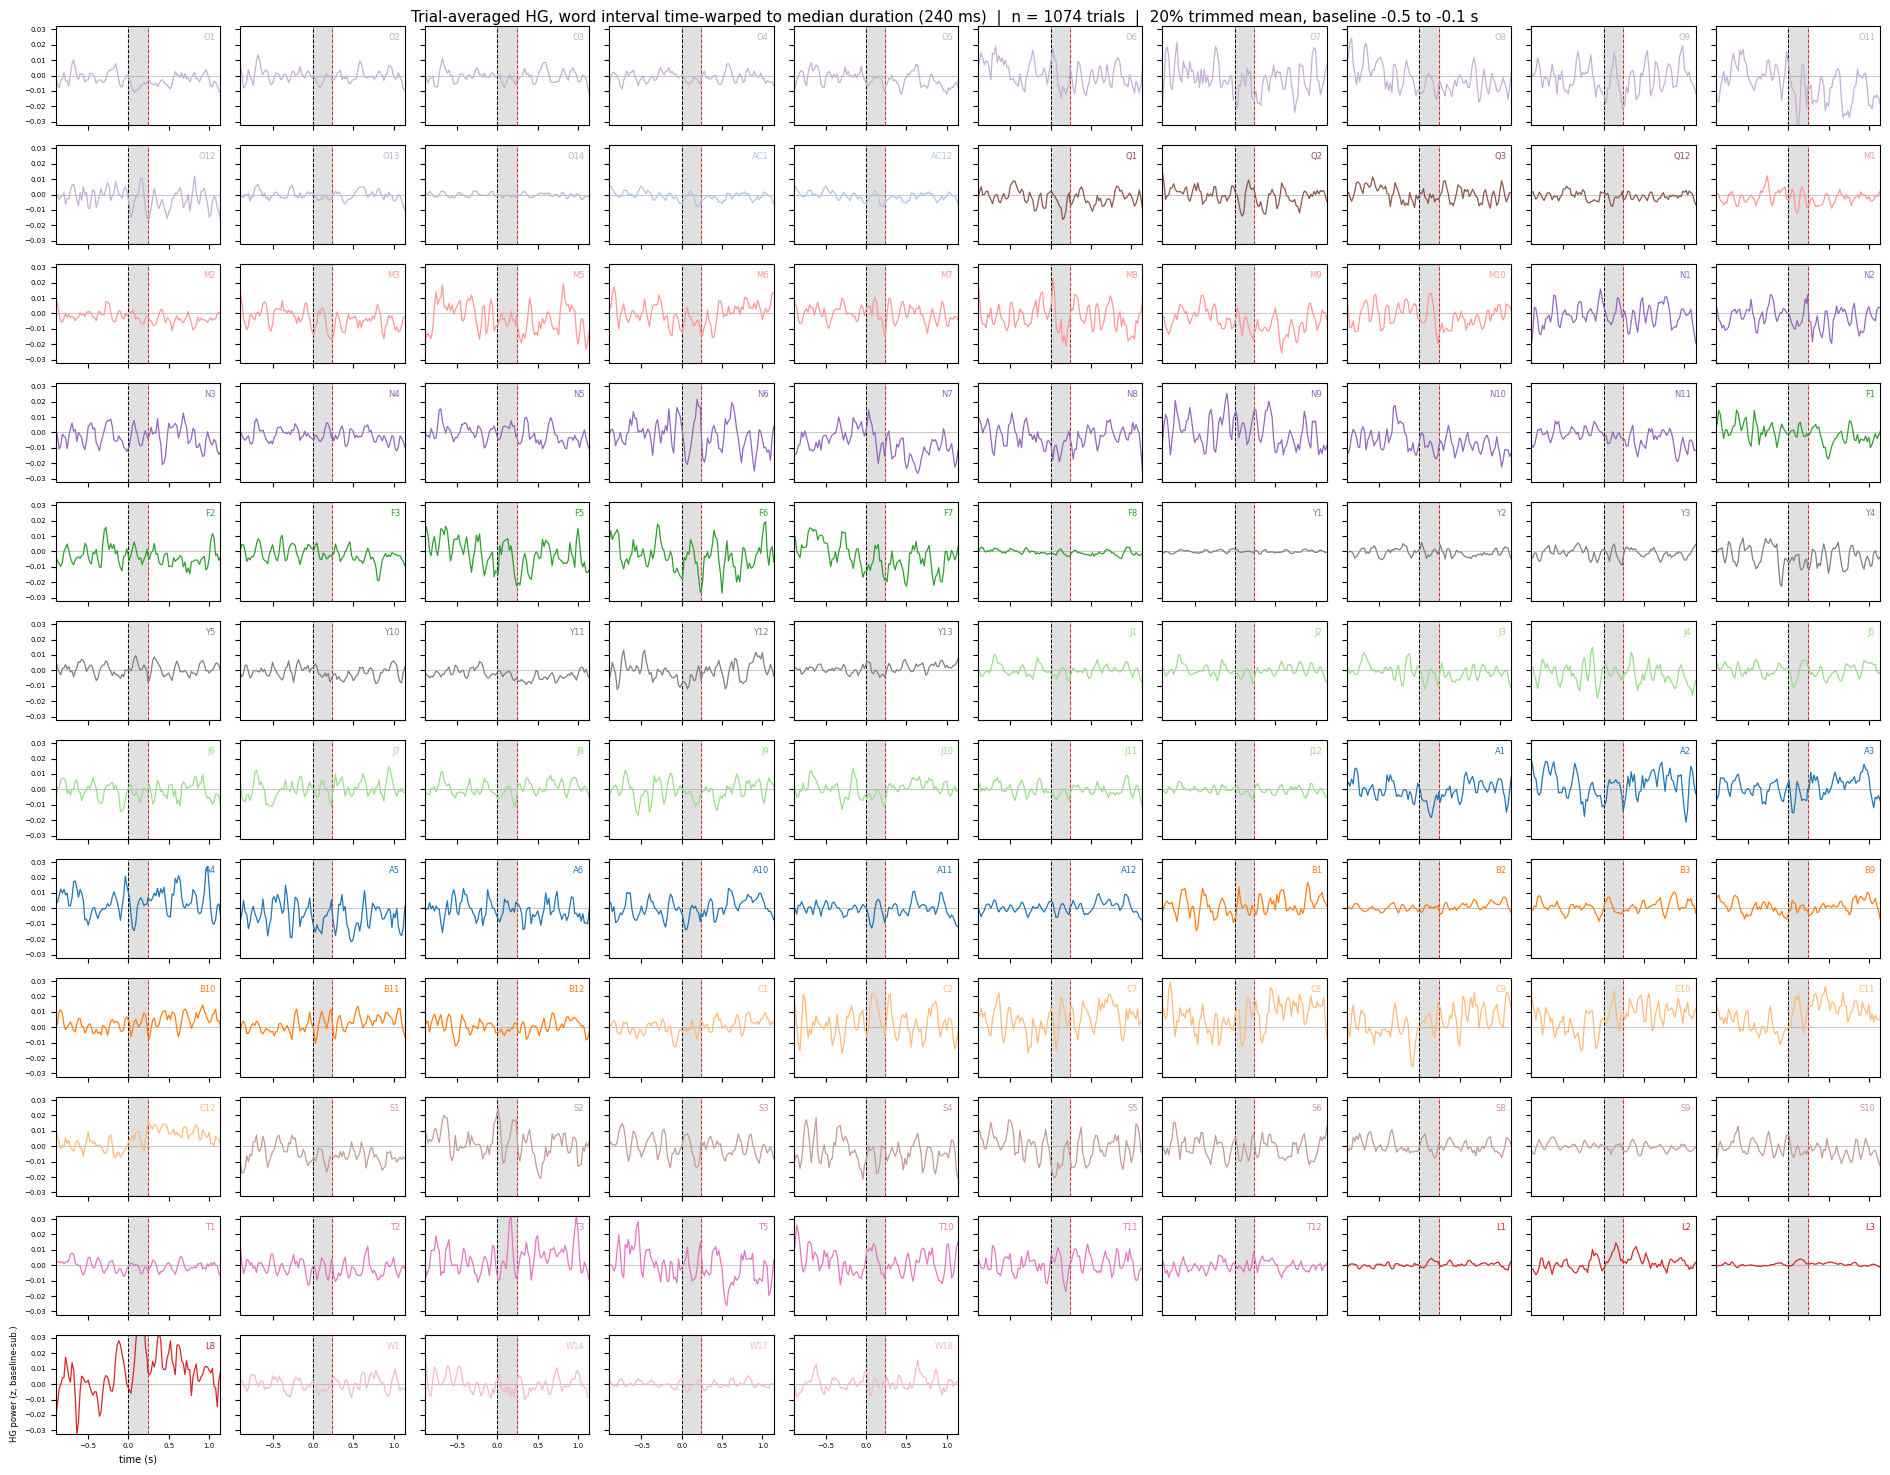

In [37]:
def channel_grid(M, tax, title, ncols=10, mark=None, mark_thresh=4.0,
                 word_span=(0.0, None), ylim=None):
    leads = [''.join(c for c in ch if c.isalpha()) for ch in CHANS]
    palette = plt.get_cmap("tab20")
    lead_col = {l: palette(i % 20) for i, l in enumerate(sorted(set(leads)))}

    nrows = int(np.ceil(NCH / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * 1.9, nrows * 1.25),
                             sharex=True, sharey=True)
    if ylim is None:
        ylim = np.percentile(np.abs(M), 99.5) * 1.4
    w0, w1 = word_span

    for k, ax in enumerate(axes.ravel()):
        if k >= NCH:
            ax.axis("off")
            continue
        if w1 is not None:
            ax.axvspan(w0, w1, color="0.88", zorder=0)
            ax.axvline(w1, ls="--", lw=0.7, c="tab:red")
        ax.axvline(w0, ls="--", lw=0.7, c="k")
        ax.axhline(0, lw=0.4, c="0.6")
        ax.plot(tax, M[:, k], lw=0.9, c=lead_col[leads[k]])
        hit = mark is not None and np.isfinite(mark[k]) and abs(mark[k]) > mark_thresh
        ax.text(0.97, 0.93, CHANS[k] + ("*" if hit else ""), transform=ax.transAxes,
                ha="right", va="top", fontsize=6,
                color="k" if hit else lead_col[leads[k]],
                fontweight="bold" if hit else "normal")
        ax.tick_params(labelsize=5)

    axes.ravel()[0].set_ylim(-ylim, ylim)
    axes.ravel()[0].set_xlim(tax[0], tax[-1])
    axes[-1, 0].set_xlabel("time (s)", fontsize=7)
    axes[-1, 0].set_ylabel("HG power (z, baseline-sub.)", fontsize=6)
    fig.suptitle(title, fontsize=11)
    fig.tight_layout()
    return fig

M = trial_avg(WARP, CLEAN, t_warp)
channel_grid(M, t_warp, mark=t_all, word_span=(0.0, MED_W),
             title=(f"Trial-averaged HG, word interval time-warped to median duration "
                    f"({MED_W*1000:.0f} ms)  |  n = {CLEAN.sum()} trials  |  "
                    f"20% trimmed mean, baseline {BASE[0]} to {BASE[1]} s"))
plt.show()

### Figure 2 — same grid, only words preceded by silence

Far fewer trials, so noisier, but the pre-onset baseline is genuinely quiet here. A real
auditory response should get **bigger**, not disappear. If a channel looks modulated in
Figure 1 but flat here, that "modulation" was probably driven by the surrounding speech
rather than by this word.

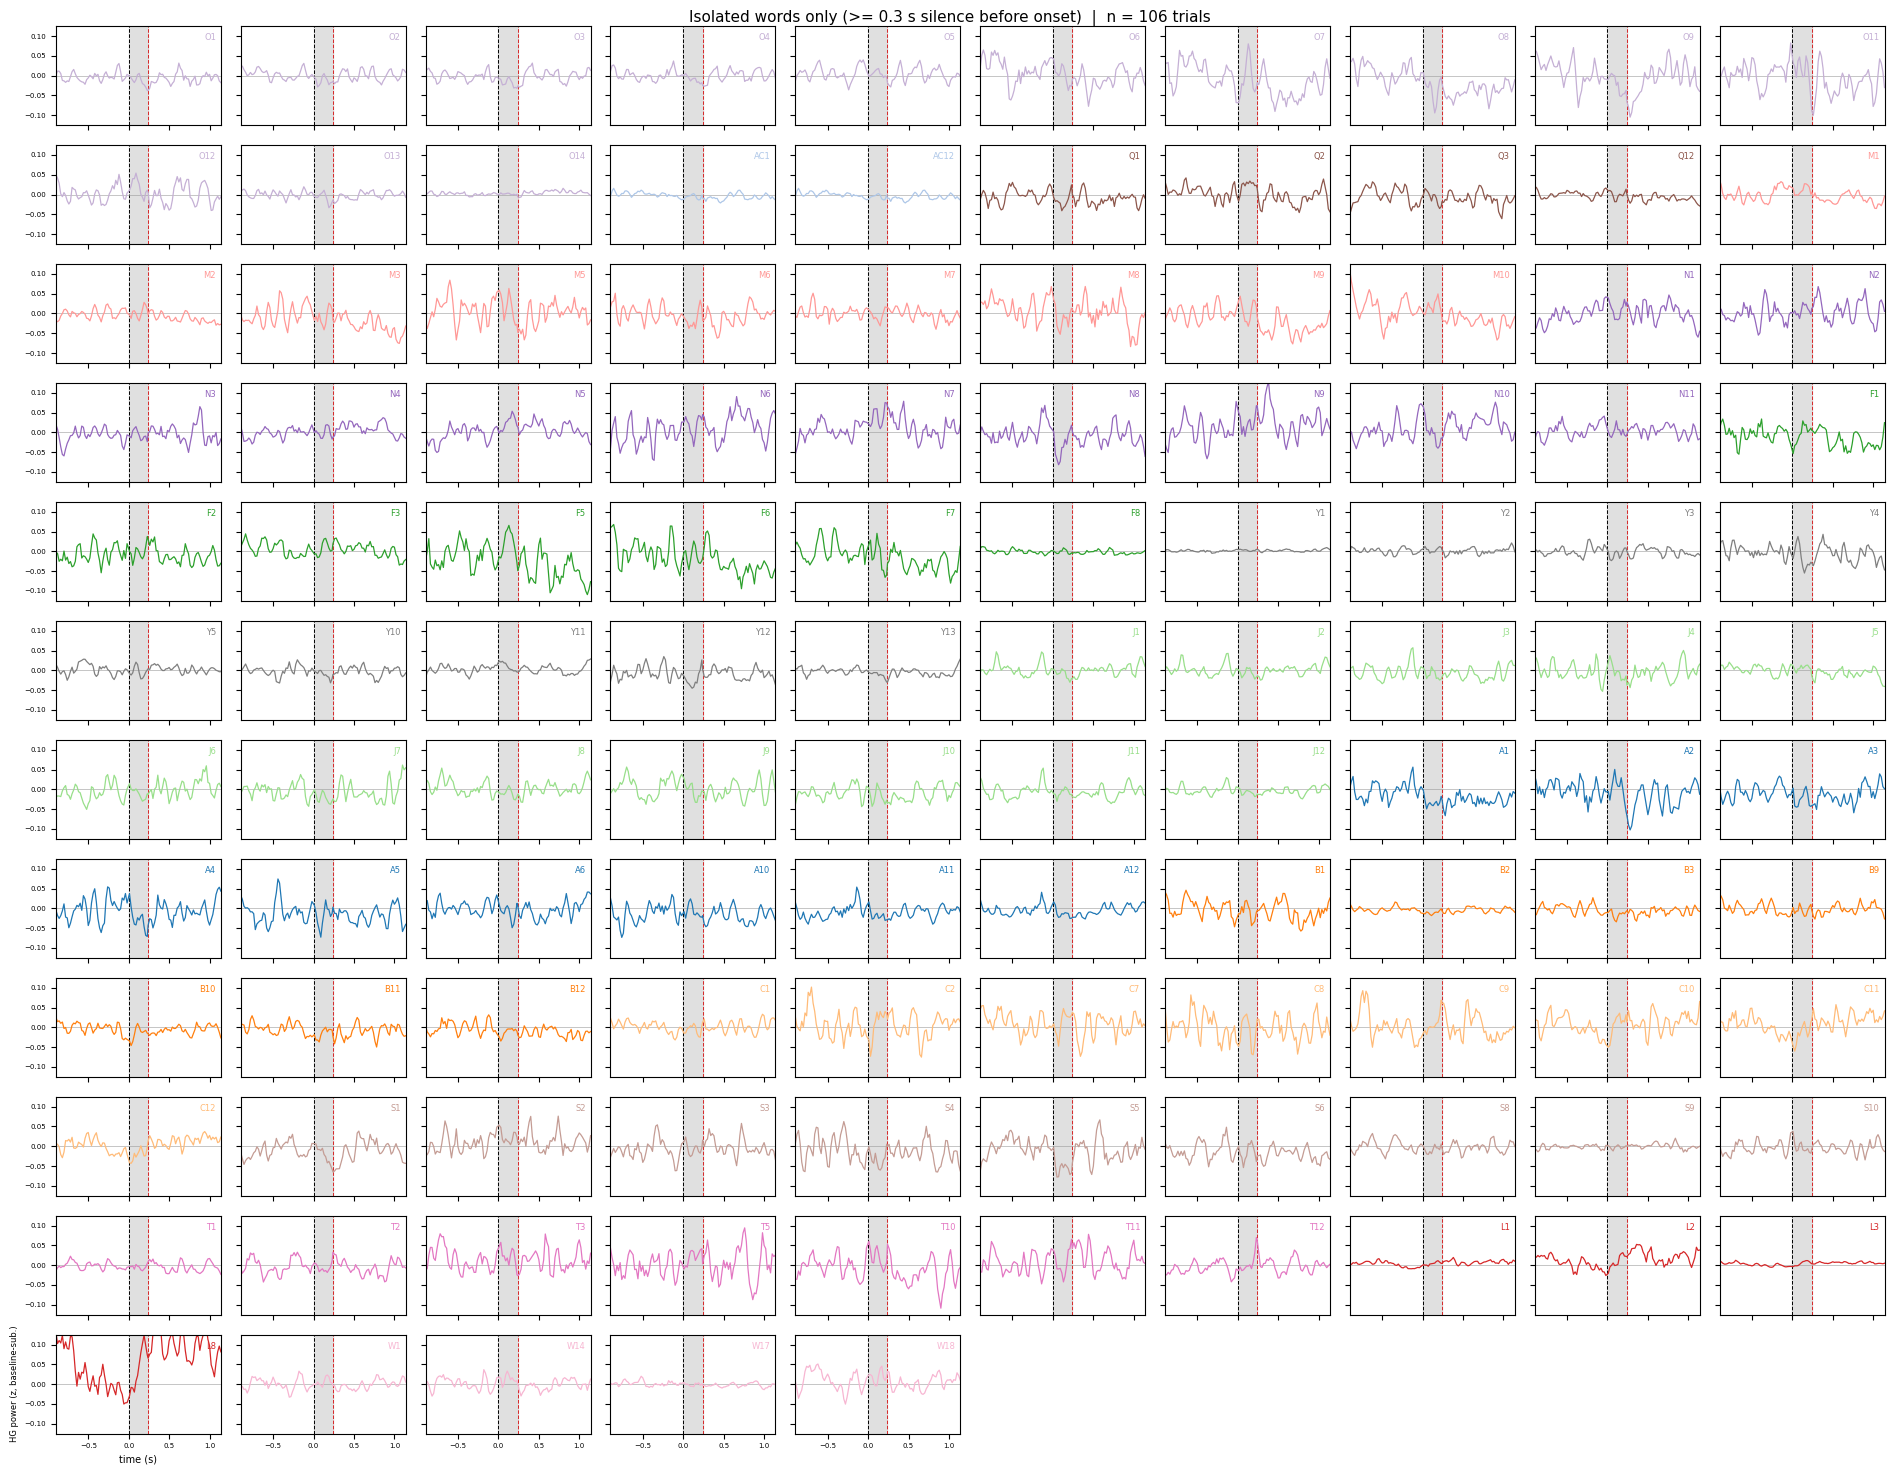

In [38]:
if ISO.sum() > 20:
    M_iso = trial_avg(WARP, ISO, t_warp)
    channel_grid(M_iso, t_warp, mark=t_iso, word_span=(0.0, MED_W),
                 title=(f"Isolated words only (>= {ISO_GAP:g} s silence before onset)  |  "
                        f"n = {ISO.sum()} trials"))
    plt.show()
else:
    print("not enough isolated-word trials to plot")

### Figure 3 — the three alignments side by side, for the most modulated channels

Onset-locked vs offset-locked vs warped. For a short-latency auditory channel the onset-locked
trace should be the sharpest; if instead the *offset*-locked trace is sharper, the epochs are
probably keyed to the wrong edge. A response that peaks *before* t = 0 in every alignment means
the epoch window is shifted (e.g. the FIR group-delay correction is off).

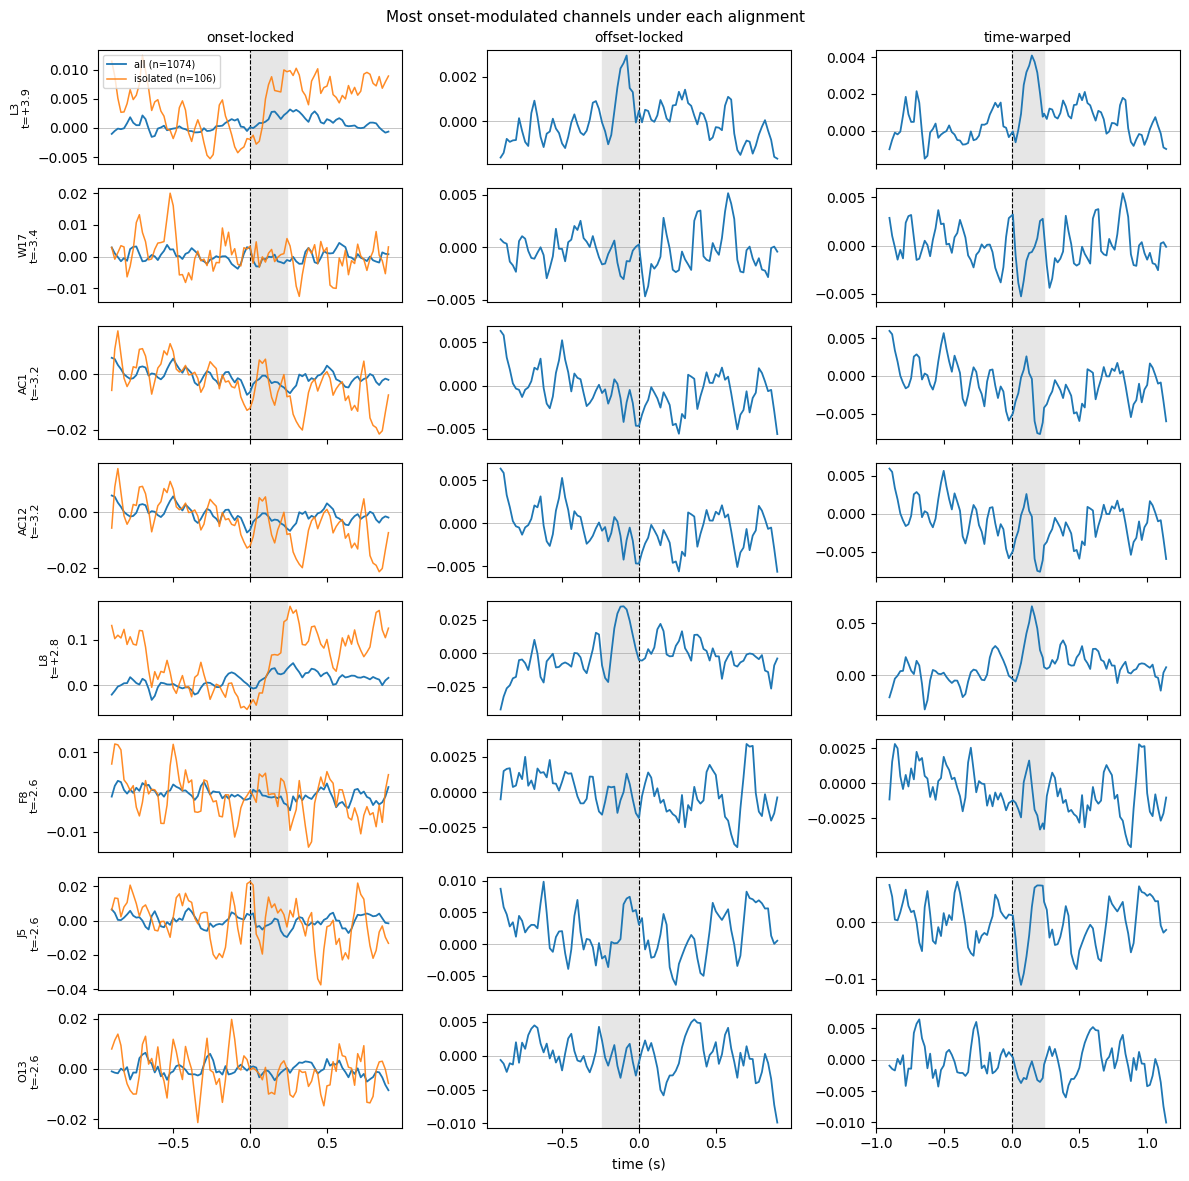

In [39]:
N_SHOW = 8
show = rank[:N_SHOW]

M_on   = trial_avg(ONSET,  CLEAN, t_on)
M_off  = trial_avg(OFFSET, CLEAN, t_off)
M_onI  = trial_avg(ONSET,  ISO,   t_on)  if ISO.sum() > 20 else None

fig, axes = plt.subplots(N_SHOW, 3, figsize=(12, 1.5 * N_SHOW), sharex="col")
for r, k in enumerate(show):
    for c, (lab, tax, M, span) in enumerate([
            ("onset-locked",  t_on,   M_on,  (0.0, MED_W)),
            ("offset-locked", t_off,  M_off, (-MED_W, 0.0)),
            ("time-warped",   t_warp, M,     (0.0, MED_W))]):
        ax = axes[r, c]
        ax.axvspan(*span, color="0.9", zorder=0)
        ax.axvline(span[0] if c != 1 else span[1], ls="--", lw=0.8, c="k")
        ax.axhline(0, lw=0.4, c="0.6")
        ax.plot(tax, M[:, k], lw=1.3, c="tab:blue",
                label=f"all (n={CLEAN.sum()})" if r == 0 else None)
        if c == 0 and M_onI is not None:
            ax.plot(t_on, M_onI[:, k], lw=1.1, c="tab:orange", alpha=0.9,
                    label=f"isolated (n={ISO.sum()})" if r == 0 else None)
        if r == 0:
            ax.set_title(lab, fontsize=10)
        if c == 0:
            ax.set_ylabel(f"{CHANS[k]}\nt={t_all[k]:+.1f}", fontsize=8)
axes[0, 0].legend(fontsize=7, loc="upper left")
axes[-1, 1].set_xlabel("time (s)")
fig.suptitle("Most onset-modulated channels under each alignment", fontsize=11)
fig.tight_layout()
plt.show()

### Figure 4 — all channels as a heatmap, plus the diagnostics that don't need eyeballing

Left: channels sorted by onset t-statistic, so any real response collects at the top and the
rest of the array should look like noise. Right: how the response scales with word duration —
split the trials into duration terciles and check that, in the warped view, short and long words
give the *same* shape (that is what the warp is for), while in the onset-locked view the
long-word trace stays elevated longer.

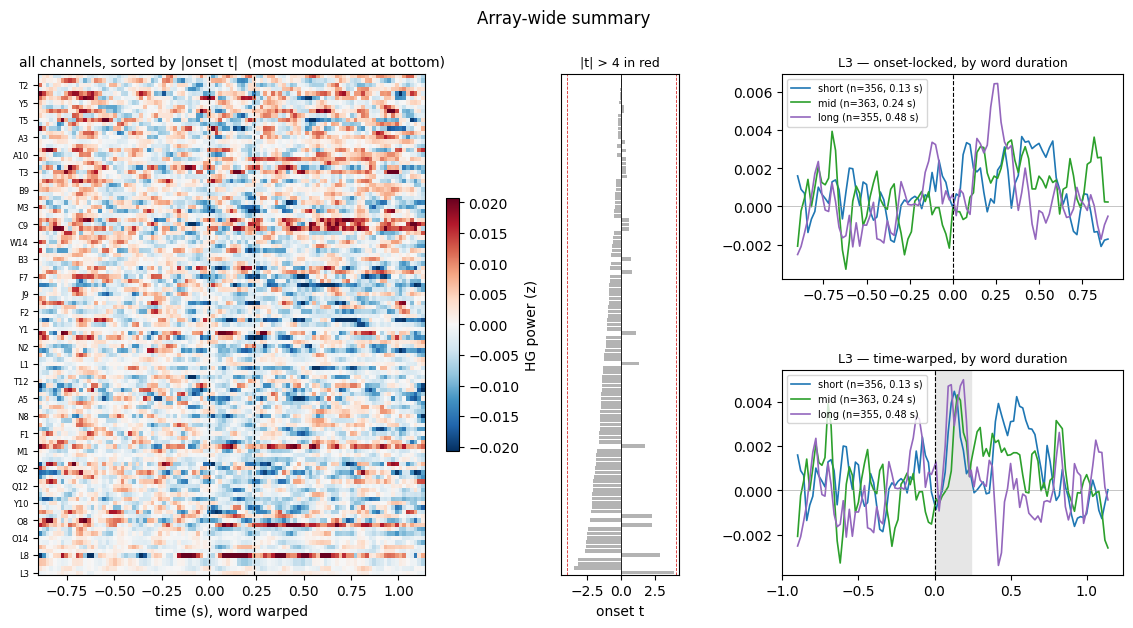

In [40]:
fig = plt.figure(figsize=(14, 6.5))
gs  = fig.add_gridspec(2, 3, width_ratios=[1.6, 0.45, 1.3], hspace=0.45, wspace=0.35)

# --- heatmap, channels sorted by onset t ---------------------------------------------------
axh = fig.add_subplot(gs[:, 0])
srt = rank
v   = np.percentile(np.abs(M), 99)
im  = axh.imshow(M[:, srt].T, aspect="auto", origin="lower", cmap="RdBu_r",
                 vmin=-v, vmax=v,
                 extent=[t_warp[0], t_warp[-1], -0.5, NCH - 0.5])
axh.axvline(0, ls="--", lw=0.8, c="k")
axh.axvline(MED_W, ls="--", lw=0.8, c="k")
axh.set_yticks(range(0, NCH, 4))
axh.set_yticklabels([CHANS[srt[i]] for i in range(0, NCH, 4)], fontsize=6)
axh.set_xlabel("time (s), word warped")
axh.set_title("all channels, sorted by |onset t|  (most modulated at bottom)", fontsize=10)
fig.colorbar(im, ax=axh, label="HG power (z)", fraction=0.03)

# --- t-statistic profile -------------------------------------------------------------------
axt = fig.add_subplot(gs[:, 1])
axt.barh(np.arange(NCH), t_all[srt], height=0.85,
         color=["tab:red" if abs(x) > 4 else "0.7" for x in t_all[srt]])
axt.axvline(0, lw=0.6, c="k")
for s in (-4, 4):
    axt.axvline(s, lw=0.6, ls="--", c="tab:red")
axt.set_ylim(-0.5, NCH - 0.5)
axt.set_yticks([])
axt.set_xlabel("onset t")
axt.set_title("|t| > 4 in red", fontsize=9)

# --- duration terciles -----------------------------------------------------------------------
q1, q2 = np.percentile(word_dur[CLEAN], [33, 67])
terciles = [("short", CLEAN & (word_dur <= q1)),
            ("mid",   CLEAN & (word_dur > q1) & (word_dur <= q2)),
            ("long",  CLEAN & (word_dur > q2))]
best = rank[0]

for row, (nm, tax, arr, span) in enumerate([
        ("onset-locked", t_on,   ONSET, None),
        ("time-warped",  t_warp, WARP,  (0.0, MED_W))]):
    ax = fig.add_subplot(gs[row, 2])
    for (lbl, msk), c in zip(terciles, ["tab:blue", "tab:green", "tab:purple"]):
        ax.plot(tax, trial_avg(arr, msk, tax)[:, best], lw=1.2, c=c,
                label=f"{lbl} (n={msk.sum()}, {word_dur[msk].mean():.2f} s)")
    if span:
        ax.axvspan(*span, color="0.9", zorder=0)
    ax.axvline(0, ls="--", lw=0.8, c="k")
    ax.axhline(0, lw=0.4, c="0.6")
    ax.set_title(f"{CHANS[best]} — {nm}, by word duration", fontsize=9)
    ax.legend(fontsize=7)
fig.suptitle("Array-wide summary", fontsize=12)
plt.show()

### What to conclude

- **Preprocessing looks right** if: a small, spatially contiguous set of channels shows a step up
  at the black onset line, that response is larger in the isolated-word subset, it is sharper
  onset-locked than offset-locked, and the warped traces for short/mid/long words superimpose.
- **Suspect a timing bug** if the response leads t = 0, or if the sharpest edge sits at the word
  offset instead. The knob is now `FIR_DELAY_S` in this notebook (~0.2 s), not something baked
  into the .mat — set it to 0 and re-run to see which way it moves. A response that arrives ~0.2 s
  *late* everywhere means the correction is being applied twice; one that *leads* t = 0 by ~0.2 s
  means it is not being applied at all.
- **Suspect a channel-order bug** if the modulated channels are scattered across unrelated leads
  rather than clustered on one depth. The channel names here are *reconstructed* from
  `parameters.ChannelNames` by re-applying the white-matter removal, since the continuous save no
  longer stores them; the count is checked against the matrix but the ordering is not, so this is
  the labelling most worth being suspicious of.
- Channels that are near-flat with occasional huge spikes (visible before artifact rejection) are
  the ones worth checking against the bad-channel list. Note no `*_bad.mat` file exists for these
  runs, so `prepare_data.m` ran with an empty bad-channel list and **no channels were excluded for
  being bad** — only white matter was removed.